# Toy implementation of the finite-state risk-reconstruction formula — Colab version

---

This notebook simulates the toy experiment from the paper.  We work on the finite state space
$\Omega=\{0,1/(B-1),\ldots,1\}$, query short-call payoffs $X_K=-(S_1-K)_+$, and generate synthetic user quotes from Expected Shortfall with a hidden strike-dependent confidence profile $q_\Lambda(K)$.  The parameter $\Lambda$ controls how inconsistent the user's risk tolerance is across strikes: $\Lambda=0$ means a constant ES level, while larger $\Lambda$ means more variation across instruments.

The reconstruction formula is evaluated by directly solving the simplex problem
$$
\phi(z)=\min_{\lambda\in\Delta_N}\left\{\tilde y^\top\lambda+L\|z-Z\lambda\|_{2,p}\right\},
$$
using `scipy.optimize.minimize` with SLSQP.  No `cvxpy` is used.

This Colab-optimized version saves all outputs persistently into Google Drive, if run inside Colab: PDF figures go to `toy_es_reconstruction_outputs/figures/`, while CSV summaries and LaTeX tables go to `toy_es_reconstruction_outputs/`.  The final cell also bundles the PDFs, `.tex` files, and `.csv` files into one zip archive.

The final section runs three ablation studies, each over `N_DRAWS` independent draws, and reports mean performance together with one empirical standard deviation band in both plots and LaTeX tables.  The ablation loops use progress bars with percentages, and each ablation writes its raw CSV, summary CSV, and LaTeX table immediately after that ablation finishes, so completed outputs survive even if a later cell is interrupted.  For the current quick-test configuration, `RUN_QUICK_TEST = True`, so `N_DRAWS = 3`; for the fuller run, set `RUN_QUICK_TEST = False`, which uses `N_DRAWS = 10`.

---

## What is being computed?

This notebook computes the finite-state version of our cash-additive convex reconstruction formula.  Given finitely many elicited risk quotes
$$
    \mathcal D_N=\{(x_n,y_n)\}_{n=1}^N
    \subseteq \mathbb R^B\times \mathbb R,
$$
the goal is to construct a globally defined risk functional which interpolates these quotes and has controlled Lipschitz regularity.

The reconstruction first removes the cash direction.  If \(p\in\Delta_B\) is the probability vector, then each payoff \(x\in\mathbb R^B\) is decomposed into its cash component \(p^\top x\) and its centered component
$$
    z=x-(p^\top x)\mathbf 1.
$$
For the training data we set
$$
    z_n=x_n-(p^\top x_n)\mathbf 1,
    \qquad
    \tilde y_n=y_n+p^\top x_n.
$$
On the reduced space, the notebook computes the convexified McShane envelope
$$
    \phi(z)
    =
    \min_{\lambda\in\Delta_N}
    \left\{
        \sum_{n=1}^N \lambda_n\tilde y_n
        +
        L\left\|
            z-\sum_{n=1}^N\lambda_n z_n
        \right\|_{2,p}
    \right\}.
$$
This is the convex McShane-Whitney reconstruction associated with the shifted data \((z_n,\tilde y_n)\).  It is the convexification of the usual upper McShane envelope, rather than the raw envelope itself.

Finally, the reduced function \(\phi\) is lifted back to a cash-additive risk functional by
$$
    \rho_{\mathcal D_N,L}(x)
    =
    \phi\bigl(x-(p^\top x)\mathbf 1\bigr)-p^\top x.
$$
This makes cash-additivity automatic.  Indeed, for any \(a\in\mathbb R\),
$
    \rho_{\mathcal D_N,L}(x+a\mathbf 1)
    =
    \rho_{\mathcal D_N,L}(x)-a
$.

The notebook therefore computes the cash-additive lift of the convexified McShane envelope.  It does not compute the monotone hull
$$
    \rho_{\mathcal D_N,L}^{\uparrow}(x)
    =
    \inf\{\rho_{\mathcal D_N,L}(y):y\le x\},
$$
which would be an additional optimization step.  Consequently, the computed object is cash-additive and convex by construction, but monotonicity is not imposed unless the monotone hull is subsequently applied.

---

## Imports, plotting style, and persistent output folder

We only need NumPy/Pandas for data handling, SciPy for the simplex solver, and Matplotlib for plots.  We use a minimal Seaborn theme for cleaner figures and `tqdm` progress bars for the repeated ablation loops.  In Colab, the cell below mounts Google Drive and saves every generated PDF, CSV, and LaTeX table persistently under `MyDrive/toy_es_reconstruction_outputs/`.  Outside Colab, the same folder is created locally.


In [ ]:
import numpy as np
import pandas as pd

from scipy.optimize import minimize
from tqdm.auto import tqdm

import matplotlib.pyplot as plt
import os
import zipfile
from pathlib import Path

# ------------------------------------------------------------
# Minimal Seaborn plotting style
# ------------------------------------------------------------
# This keeps the figures clean without changing the code structure below.
try:
    import seaborn as sns
    sns.set_theme(
        style='whitegrid',
        context='paper',
        font_scale=1.05,
        rc={
            'figure.dpi': 120,
            'savefig.dpi': 300,
            'axes.spines.right': False,
            'axes.spines.top': False,
        },
    )
    USE_SEABORN_STYLE = True
except Exception:
    # Fallback for local environments without seaborn.
    plt.style.use('seaborn-v0_8-whitegrid')
    USE_SEABORN_STYLE = False

# ------------------------------------------------------------
# Colab / local output configuration
# ------------------------------------------------------------
# If you run this notebook in Google Colab, keep MOUNT_GOOGLE_DRIVE=True
# so that the generated PDFs, CSVs, and LaTeX tables survive runtime resets.
MOUNT_GOOGLE_DRIVE = True
OUTPUT_SUBDIR = 'toy_es_reconstruction_outputs'
DOWNLOAD_ZIP_IN_BROWSER = False  # set True in the final cell if you also want a browser download

try:
    import google.colab  # type: ignore
    IN_COLAB = True
except Exception:
    IN_COLAB = False

if IN_COLAB and MOUNT_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUTPUT_DIR = Path('/content/drive/MyDrive') / OUTPUT_SUBDIR
else:
    OUTPUT_DIR = Path(OUTPUT_SUBDIR)

FIG_DIR = OUTPUT_DIR / 'figures'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f'Running in Colab: {IN_COLAB}')
print(f'Output directory: {OUTPUT_DIR}')
print(f'Figure directory: {FIG_DIR}')
print(f'Seaborn style enabled: {USE_SEABORN_STYLE}')


Mounted at /content/drive
Running in Colab: True
Output directory: /content/drive/MyDrive/toy_es_reconstruction_outputs
Figure directory: /content/drive/MyDrive/toy_es_reconstruction_outputs/figures
Seaborn style enabled: True


## Defaults

These defaults match the small toy experiment: $N_{\mathrm{train}}=100$, $N_{\mathrm{test}}=10$, and $B=10$ states.  The ablation section later changes one of these quantities at a time.  The switch `RUN_QUICK_TEST` controls the number of independent draws: use `True` to debug quickly, then switch back to `False` for the full 100-draw tables and plots.


In [ ]:
N_train = 100
N_test = 10
B = 10

seed = 2026
rng = np.random.default_rng(seed)

Omega = np.linspace(0.0, 1.0, B)
S1 = Omega.copy()

# Uniform probability on the B terminal states.
p = np.ones(B) / B
sqrt_p = np.sqrt(p)

q_min, q_max = 0.10, 0.90
q_center = 0.5 * (q_min + q_max)

# Target Lipschitz constant of the hidden strike-dependent ES level q(K).
Lambda = 0.50

# Reconstruction regularity inflation.
# Set to 1.0 to use the empirical reduced Lipschitz constant directly.
INFLATION = 1.0

# We use the payoff from writing the call:
#     X_K = -(S_1-K)_+.
# Then rho(X)=ES_q(-X) is aligned with the monetary risk convention.
USE_SHORT_CALL_PAYOFF = True

# Repeated-draw ablations: mean ± one empirical standard deviation.
# Current quick-test defaults requested by the user.
RUN_QUICK_TEST = True
N_DRAWS = 3 if RUN_QUICK_TEST else 10
BASE_SEED = 2026
DRAW_SEEDS = [BASE_SEED + 1000 * i for i in range(N_DRAWS)]
RUN_SUFFIX = f'{N_DRAWS}draws'

print(f'RUN_QUICK_TEST = {RUN_QUICK_TEST}')
print(f'N_DRAWS = {N_DRAWS}')
print(f'INFLATION = {INFLATION}')


RUN_QUICK_TEST = True
N_DRAWS = 3
INFLATION = 1.0


## Hidden strike-dependent risk tolerance

The synthetic user is generated from a hidden analytic map $q_\Lambda:[0,1]\to(q_{\min},q_{\max})$.  We build it from a one-hidden-layer sigmoidal network and rescale it so that its empirical Lipschitz constant is at most the target value $\Lambda$ on $[0,1]$.


In [ ]:
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x)) # sigmoidal activation
#     return np.sin(x) #sinusoidal activation

class HiddenSigmoidQ:
    """
    Hidden analytic q(K) in (q_min, q_max), built from a one-hidden-layer
    sigmoidal MLP with sigmoidal readout, then scaled to have empirical
    Lipschitz constant <= Lambda on [0,1].
    """

    def __init__(self, hidden_width=8, Lambda=0.5, q_min=0.1, q_max=0.9, seed=123):
        self.rng = np.random.default_rng(seed)
        self.hidden_width = hidden_width
        self.Lambda = Lambda
        self.q_min = q_min
        self.q_max = q_max
        self.q_center = 0.5 * (q_min + q_max)

        self.w1 = self.rng.normal(0.0, 3.0, size=hidden_width)
        self.b1 = self.rng.normal(0.0, 1.0, size=hidden_width)
        self.w2 = self.rng.normal(0.0, 1.0, size=hidden_width)
        self.b2 = self.rng.normal(0.0, 0.5)

        grid = np.linspace(0.0, 1.0, 2001)
        raw = self.raw(grid)
        raw_centered = raw - np.mean(raw)

        max_abs = np.max(np.abs(raw_centered)) + 1e-12
        max_deriv = np.max(np.abs(np.gradient(raw_centered, grid))) + 1e-12

        scale_range = 0.48 * (q_max - q_min) / max_abs
        scale_lip = Lambda / max_deriv if Lambda > 0 else 0.0
        self.scale = min(scale_range, scale_lip)

        q_grid = self(grid)
        self.empirical_lip = np.max(np.abs(np.gradient(q_grid, grid)))

    def raw(self, K):
        K = np.asarray(K)
        h = sigmoid(np.outer(K, self.w1) + self.b1)
        out = sigmoid(h @ self.w2 + self.b2)
        return out

    def __call__(self, K):
        K = np.asarray(K)
        raw = self.raw(K)
        # Center by approximate average over [0,1] for stability.
        grid = np.linspace(0.0, 1.0, 1001)
        raw_mean = np.mean(self.raw(grid))
        q = self.q_center + self.scale * (raw - raw_mean)
        return np.clip(q, self.q_min + 1e-6, self.q_max - 1e-6)


q_fun = HiddenSigmoidQ(hidden_width=8, Lambda=Lambda, q_min=q_min, q_max=q_max, seed=seed)

print(f"Target Lambda: {Lambda:.3f}")
print(f"Empirical Lip(q): {q_fun.empirical_lip:.3f}")

Target Lambda: 0.500
Empirical Lip(q): 0.500


## Create dataset


### Payoff and preference functions


In [ ]:
def call_payoff(K):
    return np.maximum(S1 - K, 0.0)

def X_of_K(K):
    """
    Payoff vector X_K in R^B.

    If USE_SHORT_CALL_PAYOFF=True, X_K is the payoff from writing the call:
        X_K = -(S_1-K)_+.
    """
    C = call_payoff(K)
    return -C if USE_SHORT_CALL_PAYOFF else C

def weighted_es_loss(losses, probs, q):
    """
    Computes ES_q(losses) by the Rockafellar-Uryasev formula:
        ES_q(L) = min_eta eta + 1/(1-q) E[(L-eta)_+].
    For a finite distribution, the minimum is attained at a loss value.
    """
    losses = np.asarray(losses, dtype=float)
    probs = np.asarray(probs, dtype=float)

    candidates = np.unique(losses)
    vals = []
    for eta in candidates:
        vals.append(eta + np.sum(probs * np.maximum(losses - eta, 0.0)) / (1.0 - q))
    return float(np.min(vals))

def rho_true_of_K(K):
    """
    Hidden user quote.

    We use the monetary payoff convention:
        rho(X) = ES_q(-X).
    Thus adding cash to X lowers risk by the cash amount.
    """
    X = X_of_K(K)
    q = float(q_fun(np.array([K]))[0])
    return weighted_es_loss(-X, p, q)

def batch_X(Ks):
    return np.vstack([X_of_K(float(K)) for K in Ks])

def batch_y(Ks):
    return np.array([rho_true_of_K(float(K)) for K in Ks])

### Generate training and test data


In [ ]:
K_train = np.sort(rng.uniform(0.0, 1.0, size=N_train))
K_test = np.sort(rng.uniform(0.0, 1.0, size=N_test))

X_train = batch_X(K_train)
y_train = batch_y(K_train)

X_test = batch_X(K_test)
y_test = batch_y(K_test)

q_train = q_fun(K_train)
q_test = q_fun(K_test)

print('Et Voilà mon petit cher:')

pd.DataFrame({
    "K_train": K_train[:10],
    "q(K)": q_train[:10],
    "y": y_train[:10],
})

Et Voilà mon petit cher:


,K_train,q(K),y
0,0.001802,0.624468,0.842390
1,0.012840,0.619019,0.828813
2,0.012858,0.619010,0.828792
3,0.023632,0.613798,0.815656
4,0.058735,0.597584,0.772930
5,0.092889,0.582969,0.729101
6,0.093446,0.582740,0.728397
7,0.160274,0.557519,0.646390
8,0.177353,0.551762,0.626087
9,0.178935,0.551243,0.624218


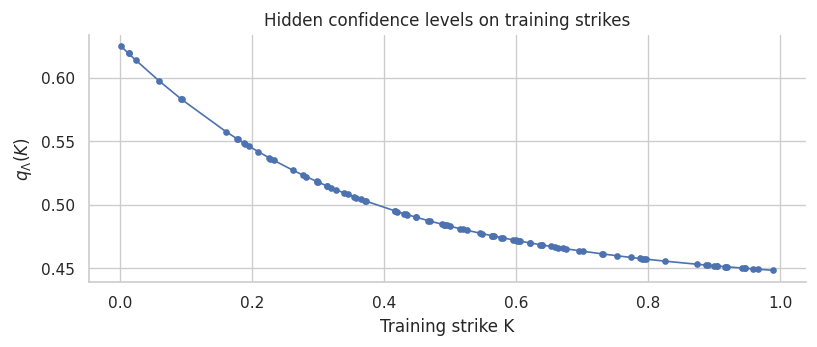

In [ ]:
plt.figure(figsize=(7, 3))
plt.plot(K_train, q_train, marker='o', markersize=3, linewidth=1)
plt.xlabel('Training strike K')
plt.ylabel(r'$q_\Lambda(K)$')
plt.title('Hidden confidence levels on training strikes')
plt.grid(True)
plt.tight_layout()
plt.savefig(FIG_DIR / 'training_q_values.pdf', bbox_inches='tight')
plt.show()


---

## Reconstruction


### Preprocessing

The formula first removes the cash direction.  For each payoff vector $x$, we compute
$z=x-(p^\top x)\mathbf 1$.  The labels are shifted by the mean via
$\tilde y_n=y_n+p^\top x_n$.


In [ ]:
def mean_p(x):
    return float(p @ x)

def project_cash_orthogonal(x):
    return x - mean_p(x) * np.ones(B)

Z_train = np.vstack([project_cash_orthogonal(x) for x in X_train])
y_tilde = y_train + X_train @ p

Zmat = Z_train.T  # B x N_train

### Reconstruction solver

This is the finite-dimensional reconstruction formula.  For each input $z$, it minimizes over the simplex $\Delta_N$.  We solve it directly with SLSQP, using the analytic gradient and warm starts when evaluating many test points.


In [ ]:
# ============================================================
# Simplex projection-free SciPy solver for the reconstruction
# No CVXPY.
# ============================================================

def solve_simplex_phi(z, L, lam0=None, maxiter=1000, tol=1e-10):
    """
    Solves

        phi(z) = min_{lambda in Delta_N}
                 y_tilde^T lambda + L ||z - Z lambda||_{2,p}

    using scipy.optimize.minimize with SLSQP.

    Here:
        Zmat is B x N_train,
        y_tilde is length N_train,
        p is length B.
    """
    z = np.asarray(z, dtype=float)

    if lam0 is None:
        lam0 = np.ones(N_train) / N_train

    def obj(lam):
        residual = z - Zmat @ lam
        norm = np.sqrt(np.sum(p * residual**2))
        return float(y_tilde @ lam + L * norm)

    def grad(lam):
        residual = z - Zmat @ lam
        norm = np.sqrt(np.sum(p * residual**2))

        # At norm=0 the norm is nonsmooth. This branch is harmless numerically.
        if norm < 1e-12:
            return y_tilde.copy()

        # d/dlam ||z-Zlam||_{2,p}
        # = - Z^T D_p (z-Zlam) / ||z-Zlam||_{2,p}
        return y_tilde - L * (Zmat.T @ (p * residual)) / norm

    constraints = [
        {
            "type": "eq",
            "fun": lambda lam: np.sum(lam) - 1.0,
            "jac": lambda lam: np.ones_like(lam),
        }
    ]

    bounds = [(0.0, 1.0) for _ in range(N_train)]

    res = minimize(
        obj,
        lam0,
        jac=grad,
        method="SLSQP",
        bounds=bounds,
        constraints=constraints,
        options={
            "maxiter": maxiter,
            "ftol": tol,
            "disp": False,
        },
    )

    if not res.success:
        # Retry from nearest-neighbor initialization.
        dists = np.sqrt(np.sum(p[:, None] * (Zmat - z[:, None])**2, axis=0))
        lam_nn = np.zeros(N_train)
        lam_nn[np.argmin(dists)] = 1.0

        res = minimize(
            obj,
            lam_nn,
            jac=grad,
            method="SLSQP",
            bounds=bounds,
            constraints=constraints,
            options={
                "maxiter": maxiter,
                "ftol": tol,
                "disp": False,
            },
        )

    if not res.success:
        raise RuntimeError(f"SLSQP failed: {res.message}")

    return float(res.fun), res.x





def phi_reconstruction(z, L, lam0=None):
    val, lam = solve_simplex_phi(z, L=L, lam0=lam0)
    return val

def rho_reconstruction(x, L, lam0=None):
    z = project_cash_orthogonal(x)
    return phi_reconstruction(z, L=L, lam0=lam0) - mean_p(x)

In [ ]:
# ============================================================
# Choose L
#
# Simple robust default:
# Use an inflated empirical pairwise Lipschitz constant on the reduced data.
# This is not guaranteed minimal.
# ============================================================

def empirical_pairwise_L(Z, y_tilde, eps=1e-12):
    Ls = []
    N = len(y_tilde)
    for i in range(N):
        for j in range(i + 1, N):
            dz = Z[i] - Z[j]
            dist = np.sqrt(np.sum(p * dz**2))
            if dist > eps:
                Ls.append(abs(y_tilde[i] - y_tilde[j]) / dist)
    return float(np.max(Ls)) if Ls else 0.0

L_emp = empirical_pairwise_L(Z_train, y_tilde)
L_recon = 2.0 * L_emp + 1e-8

print(f"Empirical pairwise L: {L_emp:.6f}")
print(f"Using reconstruction L: {L_recon:.6f}")

Empirical pairwise L: 1.277743
Using reconstruction L: 2.555485


---

## Single-draw plots


---

In [ ]:
# ============================================================
# Plots
# ============================================================

K_grid = np.linspace(0.0, 1.0, 100)
q_grid = q_fun(K_grid)
X_grid = batch_X(K_grid)
y_grid = batch_y(K_grid)

Grid reconstruction:   0%|          | 0/100 [00:00<?, ?strike/s]

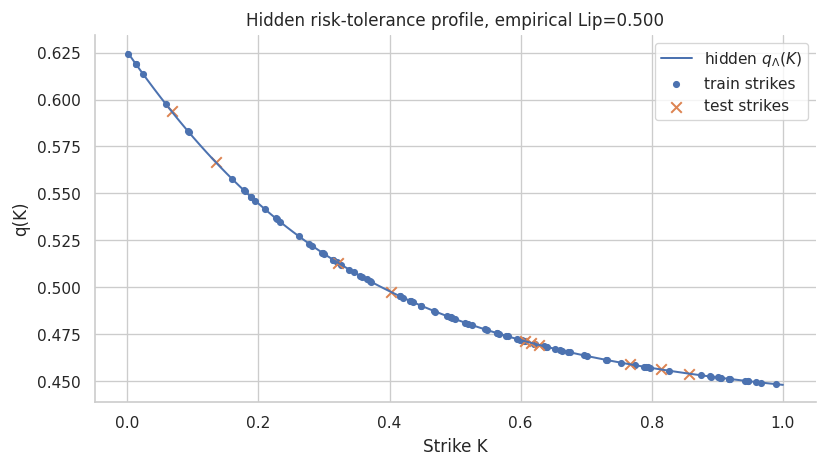

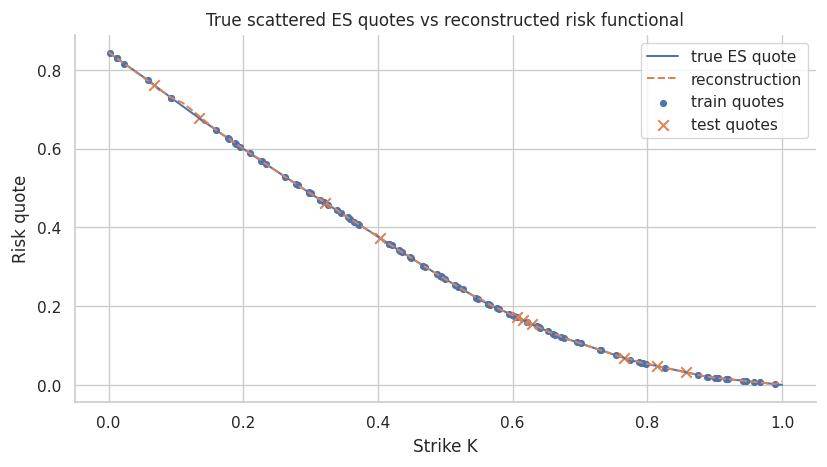

In [ ]:
# Plotting on a grid solves one simplex problem per plotted strike.  Warm starts make this faster.
y_recon_grid = []
lam_warm = np.ones(N_train) / N_train

for x in tqdm(X_grid, desc='Grid reconstruction', unit='strike'):
    z = project_cash_orthogonal(x)
    val, lam_warm = solve_simplex_phi(z, L=L_recon, lam0=lam_warm)
    y_recon_grid.append(val - mean_p(x))

y_recon_grid = np.array(y_recon_grid)

plt.figure(figsize=(7, 4))
plt.plot(K_grid, q_grid, label=r"hidden $q_\Lambda(K)$")
plt.scatter(K_train, q_train, s=12, label="train strikes")
plt.scatter(K_test, q_test, s=40, marker="x", label="test strikes")
plt.xlabel("Strike K")
plt.ylabel("q(K)")
plt.title(f"Hidden risk-tolerance profile, empirical Lip={q_fun.empirical_lip:.3f}")
plt.legend()
plt.grid(True)
if USE_SEABORN_STYLE:
    sns.despine()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "hidden_q_profile.pdf"), bbox_inches="tight")
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(K_grid, y_grid, label="true ES quote")
plt.plot(K_grid, y_recon_grid, linestyle="--", label="reconstruction")
plt.scatter(K_train, y_train, s=12, label="train quotes")
plt.scatter(K_test, y_test, s=40, marker="x", label="test quotes")
plt.xlabel("Strike K")
plt.ylabel("Risk quote")
plt.title("True scattered ES quotes vs reconstructed risk functional")
plt.legend()
plt.grid(True)
if USE_SEABORN_STYLE:
    sns.despine()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "single_draw_reconstruction.pdf"), bbox_inches="tight")
plt.show()


# Ablation studies

The next cells run three ablation studies.  Each point in each ablation is averaged over `N_DRAWS` independent draws.  We report the empirical mean and one empirical standard deviation.  The standard-deviation band is visualized with low alpha in the plots.

The current notebook defaults are deliberately quick: `RUN_QUICK_TEST=True`, hence `N_DRAWS=3`, and `INFLATION=1.0`.  For a fuller run, set `RUN_QUICK_TEST=False`, which gives `N_DRAWS=10` under the current configuration.

The three studies vary:

1. the heterogeneity parameter $\Lambda$ controlling $\operatorname{Lip}(q_\Lambda)$;
2. the number of states $B$;
3. the number of training quotes $N_{\mathrm{train}}$.


## General solver and experiment runner

This version is local in $B$, $N_{\mathrm{train}}$, and $\Lambda$, so it can be reused across all ablations.  The reconstruction is still the same simplex problem, but all state-space-dependent objects are rebuilt inside the experiment.


In [ ]:
def solve_simplex_phi_general(z, L, Zmat, y_tilde, p_local, lam0=None, maxiter=1000, tol=1e-10):
    # Solve phi(z)=min_{lambda in Delta_N} y_tilde^T lambda + L ||z-Zlambda||_{2,p}.
    z = np.asarray(z, dtype=float)
    p_local = np.asarray(p_local, dtype=float)
    N_local = Zmat.shape[1]

    if lam0 is None:
        lam0 = np.ones(N_local) / N_local

    def obj(lam):
        residual = z - Zmat @ lam
        norm = np.sqrt(np.sum(p_local * residual**2))
        return float(y_tilde @ lam + L * norm)

    def grad(lam):
        residual = z - Zmat @ lam
        norm = np.sqrt(np.sum(p_local * residual**2))
        if norm < 1e-12:
            return y_tilde.copy()
        return y_tilde - L * (Zmat.T @ (p_local * residual)) / norm

    constraints = [{
        "type": "eq",
        "fun": lambda lam: np.sum(lam) - 1.0,
        "jac": lambda lam: np.ones_like(lam),
    }]

    bounds = [(0.0, 1.0) for _ in range(N_local)]

    res = minimize(
        obj,
        lam0,
        jac=grad,
        method="SLSQP",
        bounds=bounds,
        constraints=constraints,
        options={"maxiter": maxiter, "ftol": tol, "disp": False},
    )

    if not res.success:
        # Retry from the nearest-neighbor vertex of the simplex.
        dists = np.sqrt(np.sum(p_local[:, None] * (Zmat - z[:, None])**2, axis=0))
        lam_nn = np.zeros(N_local)
        lam_nn[np.argmin(dists)] = 1.0

        res = minimize(
            obj,
            lam_nn,
            jac=grad,
            method="SLSQP",
            bounds=bounds,
            constraints=constraints,
            options={"maxiter": maxiter, "ftol": tol, "disp": False},
        )

    if not res.success:
        raise RuntimeError(f"SLSQP failed: {res.message}")

    return float(res.fun), res.x


In [ ]:
def run_general_experiment(
    N_train_local=100,
    N_test_local=10,
    B_local=10,
    Lambda=0.5,
    inflation=1.0,
    seed=123,
    q_min=0.10,
    q_max=0.90,
):
    # Run one synthetic experiment and return train/test metrics.
    local_rng = np.random.default_rng(seed)

    Omega_local = np.linspace(0.0, 1.0, B_local)
    S1_local = Omega_local.copy()
    p_local = np.ones(B_local) / B_local

    q_local = HiddenSigmoidQ(
        hidden_width=8,
        Lambda=Lambda,
        q_min=q_min,
        q_max=q_max,
        seed=seed,
    )

    def mean_p_local(x):
        return float(p_local @ x)

    def project_local(x):
        return x - mean_p_local(x) * np.ones(B_local)

    def X_of_K_local(K):
        # Short-call payoff: X_K = -(S_1 - K)_+.
        return -np.maximum(S1_local - K, 0.0)

    def rho_true_local(K):
        X = X_of_K_local(K)
        q = float(q_local(np.array([K]))[0])
        # Monetary risk convention: rho(X)=ES_q(-X).
        return weighted_es_loss(-X, p_local, q)

    def batch_X_local(Ks):
        return np.vstack([X_of_K_local(float(K)) for K in Ks])

    def batch_y_local(Ks):
        return np.array([rho_true_local(float(K)) for K in Ks])

    def empirical_pairwise_L_local(Z, y_tilde, eps=1e-12):
        vals = []
        N = len(y_tilde)
        for i in range(N):
            for j in range(i + 1, N):
                dz = Z[i] - Z[j]
                dist = np.sqrt(np.sum(p_local * dz**2))
                if dist > eps:
                    vals.append(abs(y_tilde[i] - y_tilde[j]) / dist)
        return float(np.max(vals)) if vals else 0.0

    K_train = np.sort(local_rng.uniform(0.0, 1.0, size=N_train_local))
    K_test = np.sort(local_rng.uniform(0.0, 1.0, size=N_test_local))

    X_train = batch_X_local(K_train)
    y_train = batch_y_local(K_train)
    X_test = batch_X_local(K_test)
    y_test = batch_y_local(K_test)

    Z_train = np.vstack([project_local(x) for x in X_train])
    y_tilde = y_train + X_train @ p_local
    Zmat = Z_train.T

    L_emp = empirical_pairwise_L_local(Z_train, y_tilde)
    L_recon = inflation * L_emp + 1e-8

    def rho_recon_batch(X_batch):
        preds = []
        lam_warm = np.ones(N_train_local) / N_train_local

        for x in X_batch:
            z = project_local(x)
            val, lam_warm = solve_simplex_phi_general(
                z=z,
                L=L_recon,
                Zmat=Zmat,
                y_tilde=y_tilde,
                p_local=p_local,
                lam0=lam_warm,
            )
            preds.append(val - mean_p_local(x))

        return np.array(preds)

    train_preds = rho_recon_batch(X_train)
    test_preds = rho_recon_batch(X_test)

    train_abs = np.abs(train_preds - y_train)
    test_abs = np.abs(test_preds - y_test)

    return {
        "B": B_local,
        "N_train": N_train_local,
        "N_test": N_test_local,
        "Lambda_target": Lambda,
        "Lambda_empirical": q_local.empirical_lip,
        "inflation": inflation,
        "L_emp": L_emp,
        "L_recon": L_recon,
        "train_MAE": float(np.mean(train_abs)),
        "train_MaxAE": float(np.max(train_abs)),
        "test_MAE": float(np.mean(test_abs)),
        "test_MaxAE": float(np.max(test_abs)),
    }


## Repeated-draw ablation helper

For each value of the ablated hyperparameter, we rerun the full synthetic experiment across `N_DRAWS` different random seeds.  The raw dataframe stores all individual runs; the summary dataframe stores mean and standard deviation across draws.


In [ ]:
def run_repeated_ablation(grid, varied_name, fixed_kwargs, n_draws=N_DRAWS, draw_seeds=DRAW_SEEDS):
    """
    Run an ablation over one hyperparameter and collect all draws.

    The progress bar reports the total number of completed draws across the
    whole ablation, including the percentage completed.  This is intentionally
    one bar per ablation, which is cleaner in Colab than deeply nested bars.
    """
    rows = []
    total = len(grid) * n_draws
    seeds = list(draw_seeds[:n_draws])

    with tqdm(
        total=total,
        desc=f'Ablation: {varied_name}',
        unit='draw',
        bar_format='{l_bar}{bar}| {n_fmt}/{total_fmt} [{percentage:3.0f}%] {elapsed}<{remaining}, {rate_fmt}{postfix}',
    ) as pbar:
        for value in grid:
            for draw_id, seed_i in enumerate(seeds):
                kwargs = dict(fixed_kwargs)

                if varied_name == 'Lambda':
                    kwargs['Lambda'] = value
                elif varied_name == 'B_local':
                    kwargs['B_local'] = value
                elif varied_name == 'N_train_local':
                    kwargs['N_train_local'] = value
                else:
                    raise ValueError(f'Unknown varied_name: {varied_name}')

                kwargs['seed'] = seed_i
                out = run_general_experiment(**kwargs)
                out['draw_id'] = draw_id
                out['draw_seed'] = seed_i
                out['varied_name'] = varied_name
                out['varied_value'] = value
                rows.append(out)

                pbar.update(1)
                pbar.set_postfix({
                    'value': value,
                    'draw': f'{draw_id + 1}/{n_draws}',
                })

    return pd.DataFrame(rows)


def summarize_repeated_ablation(raw_df, x_col):
    # Summarize repeated draws by mean and one empirical standard deviation.
    metrics = [
        'Lambda_empirical',
        'L_emp',
        'L_recon',
        'train_MAE',
        'train_MaxAE',
        'test_MAE',
        'test_MaxAE',
    ]

    grouped = raw_df.groupby(x_col)
    summary = grouped[metrics].agg(['mean', 'std']).reset_index()

    # Flatten MultiIndex columns.
    summary.columns = [
        col[0] if col[1] == '' else f'{col[0]}_{col[1]}'
        for col in summary.columns
    ]

    # If n_draws=1 during debugging, pandas reports std as NaN.  Replace those by 0.
    for col in summary.columns:
        if col.endswith('_std'):
            summary[col] = summary[col].fillna(0.0)

    summary['n_draws'] = grouped.size().values
    return summary


## Output helpers for immediate saves

The helpers below write each ablation's raw draws, summarized mean/std table, and LaTeX table as soon as that ablation finishes.  This is useful in Colab: if a later ablation is interrupted, the completed ablations have already been written to Google Drive.


In [ ]:
def format_sci_pm(mean, std, digits=2):
    # Format mean +/- std using one shared scientific exponent.
    if abs(mean) < 1e-15 and abs(std) < 1e-15:
        return r'$0 \pm 0$'

    if abs(mean) >= 1e-15:
        exponent = int(np.floor(np.log10(abs(mean))))
    else:
        exponent = int(np.floor(np.log10(abs(std))))

    mean_scaled = mean / (10 ** exponent)
    std_scaled = std / (10 ** exponent)
    return rf'$({mean_scaled:.{digits}f}\pm {std_scaled:.{digits}f})\times 10^{{{exponent}}}$'


def format_float_pm(mean, std, digits=3):
    return rf'${mean:.{digits}f}\pm {std:.{digits}f}$'


def latex_repeated_ablation_table(summary, x_col, x_label, caption, label):
    rows = []

    for _, row in summary.iterrows():
        if x_col in ['B', 'N_train', 'N_test']:
            x_entry = rf'${int(row[x_col])}$'
        else:
            x_entry = rf'${row[x_col]:.2f}$'

        rows.append(
            ' & '.join([
                x_entry,
                format_float_pm(row['Lambda_empirical_mean'], row['Lambda_empirical_std'], 3),
                format_sci_pm(row['L_recon_mean'], row['L_recon_std'], 2),
                format_sci_pm(row['test_MAE_mean'], row['test_MAE_std'], 2),
                format_sci_pm(row['test_MaxAE_mean'], row['test_MaxAE_std'], 2),
            ])
            + r' \\'
        )

    table = rf"""
\begin{{table}}[!htbp]
\centering
\small
\begin{{tabular}}{{c c c c c}}
\toprule
{x_label}
& Emp. $\operatorname{{Lip}}(q_\Lambda)$
& Recon. $L$
& Test MAE
& Test MaxAE
\\
\midrule
""" + '\n'.join(rows) + rf"""
\bottomrule
\end{{tabular}}
\caption{{{caption}  Each entry reports the mean $\pm$ one empirical standard deviation over {N_DRAWS} independent draws.}}
\label{{{label}}}
\end{{table}}
"""
    return table


def save_ablation_outputs(raw_df, summary_df, latex_table, raw_filename, summary_filename, table_filename):
    raw_path = OUTPUT_DIR / raw_filename
    summary_path = OUTPUT_DIR / summary_filename
    table_path = OUTPUT_DIR / table_filename

    raw_df.to_csv(raw_path, index=False)
    summary_df.to_csv(summary_path, index=False)
    with open(table_path, 'w') as f:
        f.write(latex_table)

    print('Saved ablation outputs:')
    print(' -', raw_path)
    print(' -', summary_path)
    print(' -', table_path)


## Run the three repeated-draw ablations

This is the main computational block.  It solves many small simplex optimization problems.  The current defaults are `RUN_QUICK_TEST=True`, `N_DRAWS=3`, and `INFLATION=1.0`; this is intended as a smoke test.  For a fuller run, set `RUN_QUICK_TEST=False`, which gives `N_DRAWS=10`.

Each ablation writes its raw CSV, summary CSV, and LaTeX table immediately after that ablation finishes, so completed outputs are saved before later ablations or plotting cells run.


In [ ]:
# Ablation 1: vary the heterogeneity of q_Lambda.
Lambda_grid = [0.0, 0.1, 0.25, 0.5, 0.75, 1.0]

raw_ablation_Lambda = run_repeated_ablation(
    grid=Lambda_grid,
    varied_name='Lambda',
    fixed_kwargs=dict(
        N_train_local=100,
        N_test_local=10,
        B_local=10,
        Lambda=0.5,       # overwritten by the grid
        inflation=INFLATION,
    ),
)

summary_Lambda = summarize_repeated_ablation(raw_ablation_Lambda, x_col='Lambda_target')

latex_lambda = latex_repeated_ablation_table(
    summary=summary_Lambda,
    x_col='Lambda_target',
    x_label=r'Target $\Lambda$',
    caption=rf'Finite-state option-risk reconstruction under heterogeneous Expected Shortfall levels with reconstruction inflation ${INFLATION}$.',
    label=rf'tab:finite_state_es_ablation_lambda_{RUN_SUFFIX}',
)

save_ablation_outputs(
    raw_df=raw_ablation_Lambda,
    summary_df=summary_Lambda,
    latex_table=latex_lambda,
    raw_filename=f'raw_ablation_Lambda_{RUN_SUFFIX}.csv',
    summary_filename=f'summary_ablation_Lambda_{RUN_SUFFIX}.csv',
    table_filename=f'ablation_lambda_table_{RUN_SUFFIX}.tex',
)

summary_Lambda


Ablation: Lambda:   0%|          | 0/18 [  0%] 00:00<?, ?draw/s

Saved ablation outputs:
 - /content/drive/MyDrive/toy_es_reconstruction_outputs/raw_ablation_Lambda_3draws.csv
 - /content/drive/MyDrive/toy_es_reconstruction_outputs/summary_ablation_Lambda_3draws.csv
 - /content/drive/MyDrive/toy_es_reconstruction_outputs/ablation_lambda_table_3draws.tex


,Lambda_target,Lambda_empirical_mean,Lambda_empirical_std,L_emp_mean,L_emp_std,L_recon_mean,L_recon_std,train_MAE_mean,train_MAE_std,train_MaxAE_mean,train_MaxAE_std,test_MAE_mean,test_MAE_std,test_MaxAE_mean,test_MaxAE_std,n_draws
0,0.00,5.684342e-14,0.000000e+00,1.000000,7.171663e-14,1.000000,7.171663e-14,1.437697e-08,8.439264e-09,5.172112e-07,6.599859e-07,0.000055,0.000032,0.000348,0.000303,3
1,0.10,1.000000e-01,2.220446e-13,1.000823,3.337326e-02,1.000823,3.337326e-02,1.068927e-05,8.700517e-06,8.949780e-05,5.998369e-05,0.000079,0.000052,0.000423,0.000421,3
2,0.25,2.500000e-01,5.874748e-13,1.017372,5.845429e-02,1.017372,5.845429e-02,3.655880e-05,4.637020e-05,6.043555e-04,8.819788e-04,0.000109,0.000076,0.000526,0.000559,3
3,0.50,5.000000e-01,1.153778e-12,1.316535,4.579058e-02,1.316535,4.579058e-02,6.941753e-05,5.449177e-05,8.850245e-04,9.579257e-04,0.000258,0.000155,0.000961,0.000818,3
4,0.75,7.500000e-01,1.666552e-12,1.870283,1.119004e-01,1.870283,1.119004e-01,6.664358e-05,6.231331e-05,8.829106e-04,5.280981e-04,0.000337,0.000185,0.001350,0.000285,3
5,1.00,1.000000e+00,2.307555e-12,2.186579,5.987858e-02,2.186579,5.987858e-02,1.136421e-04,7.692413e-05,1.749559e-03,7.245513e-04,0.000511,0.000298,0.002347,0.002344,3


In [ ]:
# Ablation 2: vary the number of terminal states B.
B_grid = [5, 10, 15, 20, 30]

raw_ablation_B = run_repeated_ablation(
    grid=B_grid,
    varied_name='B_local',
    fixed_kwargs=dict(
        N_train_local=100,
        N_test_local=10,
        B_local=10,       # overwritten by the grid
        Lambda=0.5,
        inflation=INFLATION,
    ),
)

summary_B = summarize_repeated_ablation(raw_ablation_B, x_col='B')

latex_B = latex_repeated_ablation_table(
    summary=summary_B,
    x_col='B',
    x_label=r'$B$',
    caption=rf'Finite-state option-risk reconstruction as the number of terminal states $B$ varies, with $N_{{\mathrm{{train}}}}=100$, target heterogeneity $\Lambda=0.5$, and reconstruction inflation ${INFLATION}$.',
    label=rf'tab:finite_state_es_ablation_B_{RUN_SUFFIX}',
)

save_ablation_outputs(
    raw_df=raw_ablation_B,
    summary_df=summary_B,
    latex_table=latex_B,
    raw_filename=f'raw_ablation_B_{RUN_SUFFIX}.csv',
    summary_filename=f'summary_ablation_B_{RUN_SUFFIX}.csv',
    table_filename=f'ablation_B_table_{RUN_SUFFIX}.tex',
)

summary_B


Ablation: B_local:   0%|          | 0/15 [  0%] 00:00<?, ?draw/s

Saved ablation outputs:
 - /content/drive/MyDrive/toy_es_reconstruction_outputs/raw_ablation_B_3draws.csv
 - /content/drive/MyDrive/toy_es_reconstruction_outputs/summary_ablation_B_3draws.csv
 - /content/drive/MyDrive/toy_es_reconstruction_outputs/ablation_B_table_3draws.tex


,B,Lambda_empirical_mean,Lambda_empirical_std,L_emp_mean,L_emp_std,L_recon_mean,L_recon_std,train_MAE_mean,train_MAE_std,train_MaxAE_mean,train_MaxAE_std,test_MAE_mean,test_MAE_std,test_MaxAE_mean,test_MaxAE_std,n_draws
0,5,0.5,1.153778e-12,1.495492,0.046363,1.495492,0.046363,0.000271,0.000327,0.003195,0.002144,0.000435,0.000363,0.002342,0.002034,3
1,10,0.5,1.153778e-12,1.316535,0.045791,1.316535,0.045791,0.000069,0.000054,0.000885,0.000958,0.000258,0.000155,0.000961,0.000818,3
2,15,0.5,1.153778e-12,1.327635,0.054647,1.327635,0.054647,0.000066,0.000079,0.001649,0.002124,0.000334,0.000231,0.001947,0.001504,3
3,20,0.5,1.153778e-12,1.402742,0.036980,1.402742,0.036980,0.000029,0.000022,0.000904,0.000647,0.000284,0.000143,0.001700,0.001077,3
4,30,0.5,1.153778e-12,1.609463,0.032400,1.609463,0.032400,0.000009,0.000003,0.000372,0.000156,0.000508,0.000285,0.001933,0.001111,3


In [ ]:
# Ablation 3: vary the number of training quotes N_train.
N_train_grid = [20, 40, 60, 80, 100, 150]

raw_ablation_N = run_repeated_ablation(
    grid=N_train_grid,
    varied_name='N_train_local',
    fixed_kwargs=dict(
        N_train_local=100,  # overwritten by the grid
        N_test_local=10,
        B_local=10,
        Lambda=0.5,
        inflation=INFLATION,
    ),
)

summary_N = summarize_repeated_ablation(raw_ablation_N, x_col='N_train')

latex_N = latex_repeated_ablation_table(
    summary=summary_N,
    x_col='N_train',
    x_label=r'$N_{\mathrm{train}}$',
    caption=rf'Finite-state option-risk reconstruction as the number of elicited training quotes varies, with $B=10$, target heterogeneity $\Lambda=0.5$, and reconstruction inflation ${INFLATION}$.',
    label=rf'tab:finite_state_es_ablation_Ntrain_{RUN_SUFFIX}',
)

save_ablation_outputs(
    raw_df=raw_ablation_N,
    summary_df=summary_N,
    latex_table=latex_N,
    raw_filename=f'raw_ablation_Ntrain_{RUN_SUFFIX}.csv',
    summary_filename=f'summary_ablation_Ntrain_{RUN_SUFFIX}.csv',
    table_filename=f'ablation_Ntrain_table_{RUN_SUFFIX}.tex',
)

summary_N


Ablation: N_train_local:   0%|          | 0/18 [  0%] 00:00<?, ?draw/s

Saved ablation outputs:
 - /content/drive/MyDrive/toy_es_reconstruction_outputs/raw_ablation_Ntrain_3draws.csv
 - /content/drive/MyDrive/toy_es_reconstruction_outputs/summary_ablation_Ntrain_3draws.csv
 - /content/drive/MyDrive/toy_es_reconstruction_outputs/ablation_Ntrain_table_3draws.tex


,N_train,Lambda_empirical_mean,Lambda_empirical_std,L_emp_mean,L_emp_std,L_recon_mean,L_recon_std,train_MAE_mean,train_MAE_std,train_MaxAE_mean,train_MaxAE_std,test_MAE_mean,test_MAE_std,test_MaxAE_mean,test_MaxAE_std,n_draws
0,20,0.5,1.153778e-12,1.111421,0.097754,1.111422,0.097754,0.000083,0.000052,0.001535,0.001077,0.002485,0.000439,0.009338,0.004958,3
1,40,0.5,1.153778e-12,1.163516,0.115210,1.163516,0.115210,0.000083,0.000068,0.002520,0.002801,0.000699,0.000681,0.002840,0.002804,3
2,60,0.5,1.153778e-12,1.193724,0.151776,1.193724,0.151776,0.000093,0.000104,0.002195,0.003079,0.001008,0.000619,0.007134,0.003799,3
3,80,0.5,1.153778e-12,1.292146,0.036376,1.292146,0.036376,0.000068,0.000051,0.001037,0.000857,0.000283,0.000096,0.001666,0.001206,3
4,100,0.5,1.153778e-12,1.316535,0.045791,1.316535,0.045791,0.000069,0.000054,0.000885,0.000958,0.000258,0.000155,0.000961,0.000818,3
5,150,0.5,1.153778e-12,1.345045,0.034250,1.345045,0.034250,0.000054,0.000051,0.000694,0.000685,0.000073,0.000054,0.000260,0.000115,3


In [ ]:
# The raw CSVs, summary CSVs, and LaTeX tables were already written immediately
# after each ablation finished.  This cell is only a quick check/listing.
expected_outputs = [
    'raw_ablation_Lambda_100draws.csv',
    'summary_ablation_Lambda_100draws.csv',
    'ablation_lambda_table_100draws.tex',
    'raw_ablation_B_100draws.csv',
    'summary_ablation_B_100draws.csv',
    'ablation_B_table_100draws.tex',
    'raw_ablation_Ntrain_100draws.csv',
    'summary_ablation_Ntrain_100draws.csv',
    'ablation_Ntrain_table_100draws.tex',
]

print('Completed ablation outputs currently expected in:', OUTPUT_DIR)
for filename in expected_outputs:
    path = OUTPUT_DIR / filename
    print(f"{'✓' if path.exists() else 'missing'} {path}")


Completed ablation outputs currently expected in: /content/drive/MyDrive/toy_es_reconstruction_outputs
missing /content/drive/MyDrive/toy_es_reconstruction_outputs/raw_ablation_Lambda_100draws.csv
missing /content/drive/MyDrive/toy_es_reconstruction_outputs/summary_ablation_Lambda_100draws.csv
missing /content/drive/MyDrive/toy_es_reconstruction_outputs/ablation_lambda_table_100draws.tex
missing /content/drive/MyDrive/toy_es_reconstruction_outputs/raw_ablation_B_100draws.csv
missing /content/drive/MyDrive/toy_es_reconstruction_outputs/summary_ablation_B_100draws.csv
missing /content/drive/MyDrive/toy_es_reconstruction_outputs/ablation_B_table_100draws.tex
missing /content/drive/MyDrive/toy_es_reconstruction_outputs/raw_ablation_Ntrain_100draws.csv
missing /content/drive/MyDrive/toy_es_reconstruction_outputs/summary_ablation_Ntrain_100draws.csv
missing /content/drive/MyDrive/toy_es_reconstruction_outputs/ablation_Ntrain_table_100draws.tex


## Plots with one-standard-deviation bands

Each curve plots the mean over 100 independent draws.  The shaded band is one empirical standard deviation above and below the mean.  We save each figure as a PDF before calling `plt.show()`.


In [ ]:
def plot_mean_std_band(
    summary,
    x_col,
    y_mean_col,
    y_std_col,
    xlabel,
    ylabel,
    title,
    filename,
    label=None,
    alpha=0.18,
):
    x = summary[x_col].to_numpy(dtype=float)
    y = summary[y_mean_col].to_numpy(dtype=float)
    s = summary[y_std_col].to_numpy(dtype=float)

    order = np.argsort(x)
    x, y, s = x[order], y[order], s[order]

    plt.figure(figsize=(7, 4))
    plt.plot(x, y, marker='o', label=label if label is not None else 'Mean')
    plt.fill_between(x, y - s, y + s, alpha=alpha, label=r'$\pm 1$ std. dev.')
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend()
    plt.grid(True)
    if USE_SEABORN_STYLE:
        sns.despine()
    plt.tight_layout()

    path = os.path.join(FIG_DIR, filename)
    plt.savefig(path, bbox_inches='tight')
    plt.show()

    print(f'Saved: {path}')


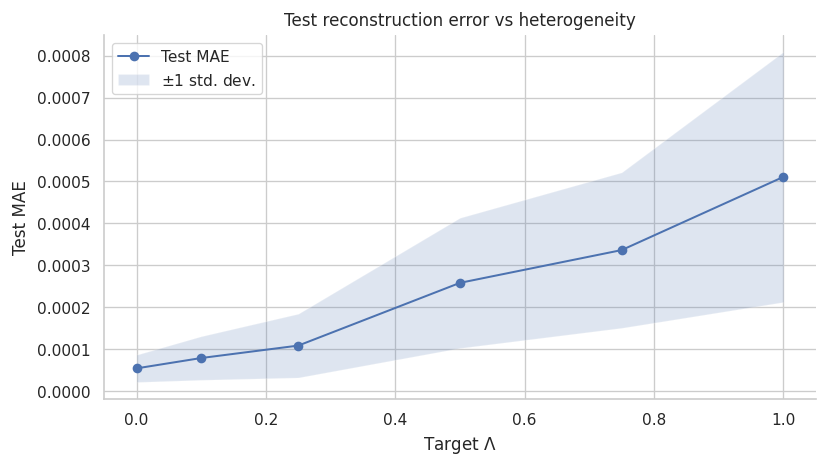

Saved: /content/drive/MyDrive/toy_es_reconstruction_outputs/figures/ablation_lambda_test_mae_mean_std.pdf


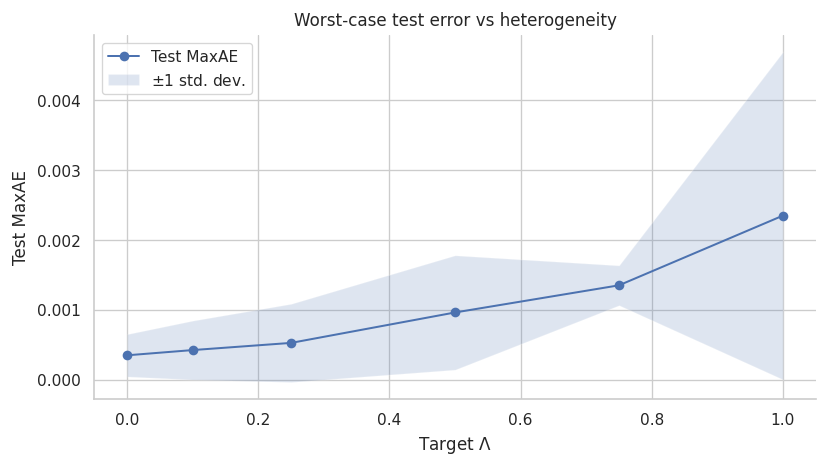

Saved: /content/drive/MyDrive/toy_es_reconstruction_outputs/figures/ablation_lambda_test_maxae_mean_std.pdf


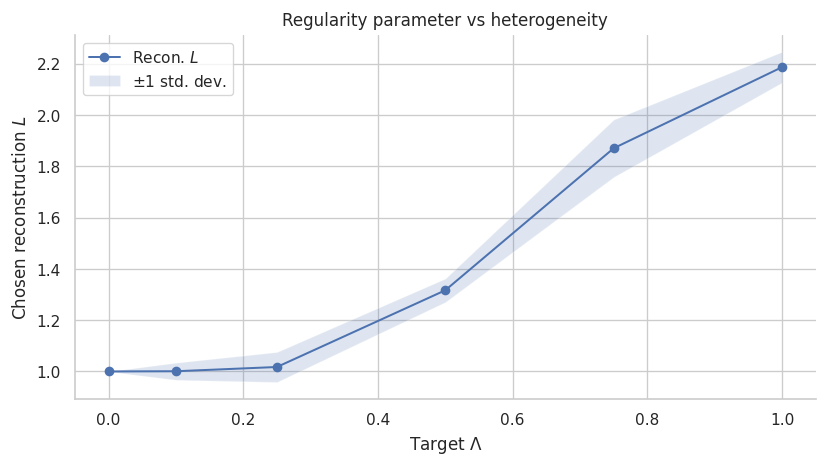

Saved: /content/drive/MyDrive/toy_es_reconstruction_outputs/figures/ablation_lambda_Lrecon_mean_std.pdf


In [ ]:
# Lambda ablation plots.
plot_mean_std_band(
    summary=summary_Lambda,
    x_col="Lambda_target",
    y_mean_col="test_MAE_mean",
    y_std_col="test_MAE_std",
    xlabel=r"Target $\Lambda$",
    ylabel="Test MAE",
    title=r"Test reconstruction error vs heterogeneity",
    filename="ablation_lambda_test_mae_mean_std.pdf",
    label="Test MAE",
)

plot_mean_std_band(
    summary=summary_Lambda,
    x_col="Lambda_target",
    y_mean_col="test_MaxAE_mean",
    y_std_col="test_MaxAE_std",
    xlabel=r"Target $\Lambda$",
    ylabel="Test MaxAE",
    title=r"Worst-case test error vs heterogeneity",
    filename="ablation_lambda_test_maxae_mean_std.pdf",
    label="Test MaxAE",
)

plot_mean_std_band(
    summary=summary_Lambda,
    x_col="Lambda_target",
    y_mean_col="L_recon_mean",
    y_std_col="L_recon_std",
    xlabel=r"Target $\Lambda$",
    ylabel=r"Chosen reconstruction $L$",
    title=r"Regularity parameter vs heterogeneity",
    filename="ablation_lambda_Lrecon_mean_std.pdf",
    label=r"Recon. $L$",
)


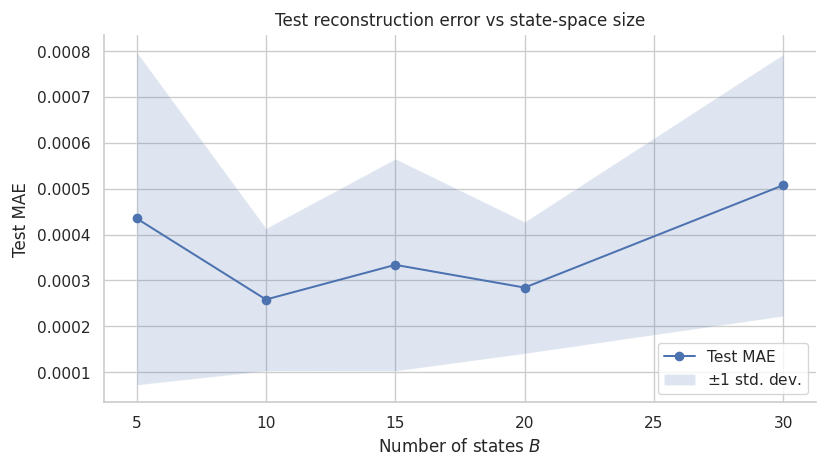

Saved: /content/drive/MyDrive/toy_es_reconstruction_outputs/figures/ablation_B_test_mae_mean_std.pdf


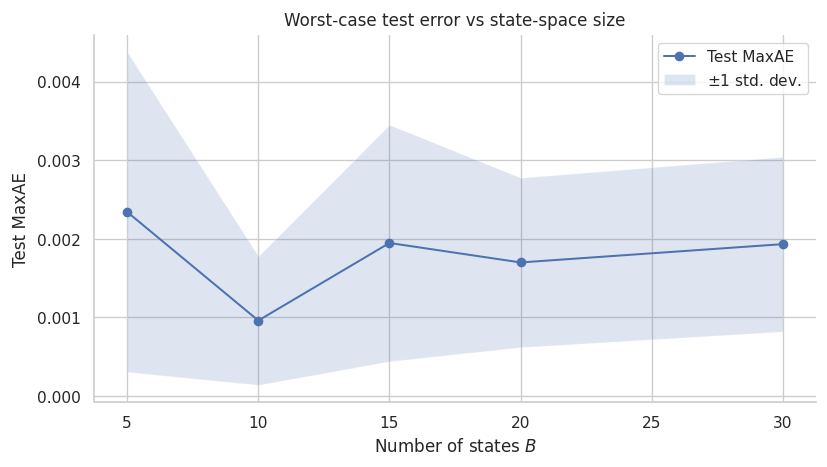

Saved: /content/drive/MyDrive/toy_es_reconstruction_outputs/figures/ablation_B_test_maxae_mean_std.pdf


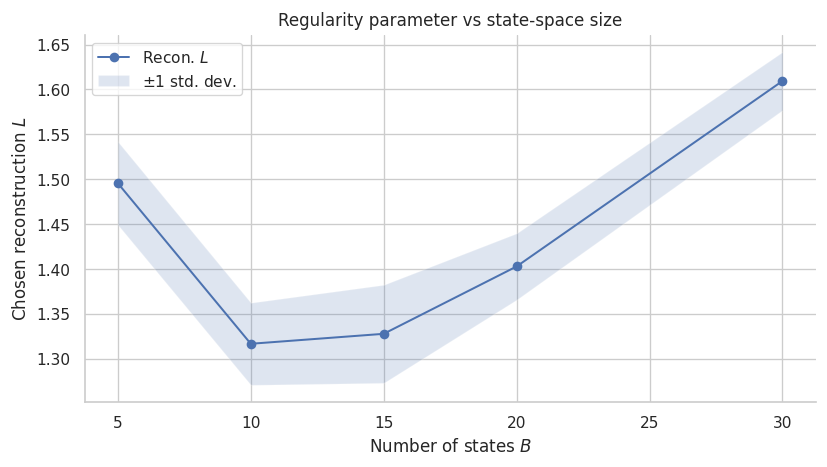

Saved: /content/drive/MyDrive/toy_es_reconstruction_outputs/figures/ablation_B_Lrecon_mean_std.pdf


In [ ]:
# B ablation plots.
plot_mean_std_band(
    summary=summary_B,
    x_col="B",
    y_mean_col="test_MAE_mean",
    y_std_col="test_MAE_std",
    xlabel=r"Number of states $B$",
    ylabel="Test MAE",
    title=r"Test reconstruction error vs state-space size",
    filename="ablation_B_test_mae_mean_std.pdf",
    label="Test MAE",
)

plot_mean_std_band(
    summary=summary_B,
    x_col="B",
    y_mean_col="test_MaxAE_mean",
    y_std_col="test_MaxAE_std",
    xlabel=r"Number of states $B$",
    ylabel="Test MaxAE",
    title=r"Worst-case test error vs state-space size",
    filename="ablation_B_test_maxae_mean_std.pdf",
    label="Test MaxAE",
)

plot_mean_std_band(
    summary=summary_B,
    x_col="B",
    y_mean_col="L_recon_mean",
    y_std_col="L_recon_std",
    xlabel=r"Number of states $B$",
    ylabel=r"Chosen reconstruction $L$",
    title=r"Regularity parameter vs state-space size",
    filename="ablation_B_Lrecon_mean_std.pdf",
    label=r"Recon. $L$",
)


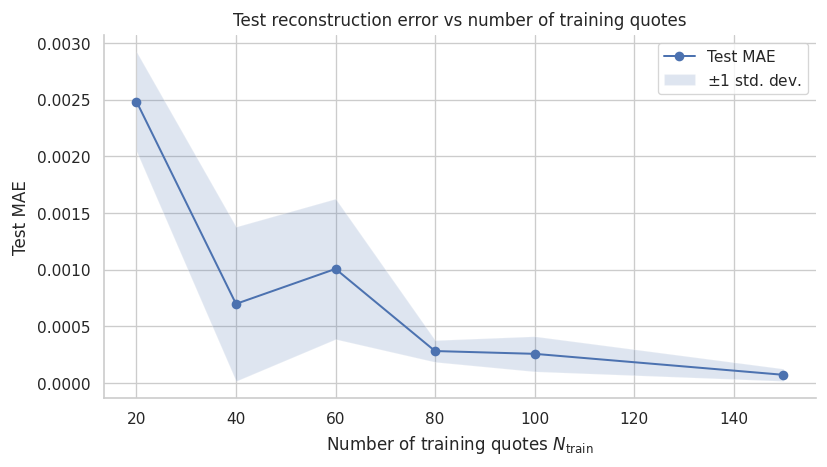

Saved: /content/drive/MyDrive/toy_es_reconstruction_outputs/figures/ablation_Ntrain_test_mae_mean_std.pdf


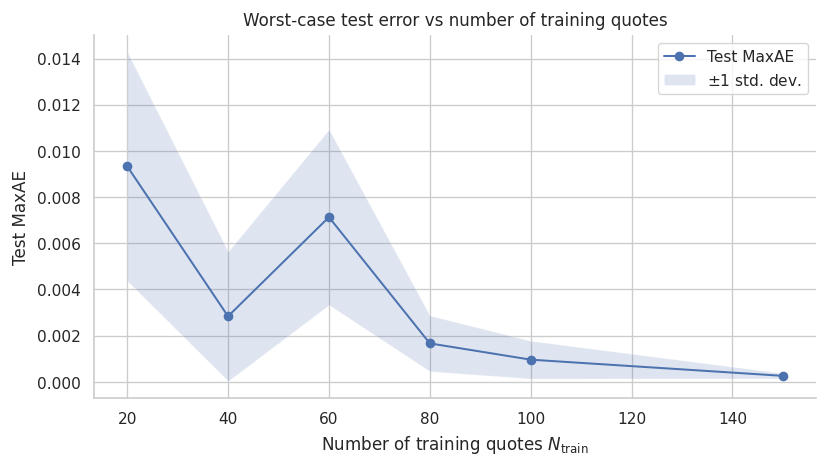

Saved: /content/drive/MyDrive/toy_es_reconstruction_outputs/figures/ablation_Ntrain_test_maxae_mean_std.pdf


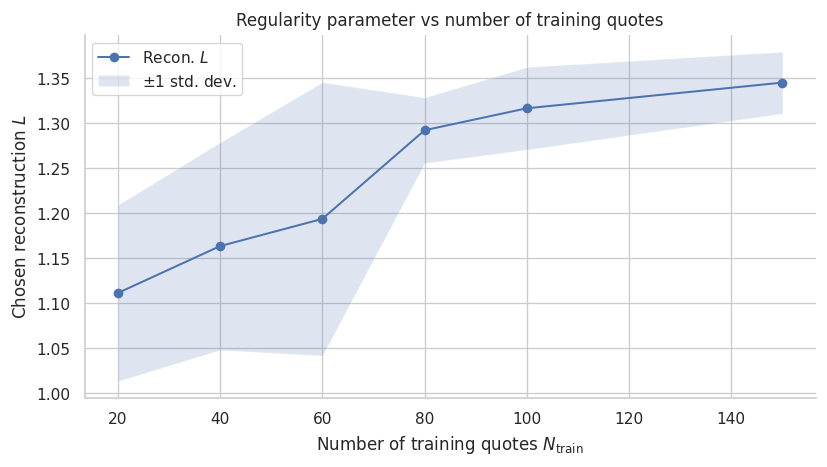

Saved: /content/drive/MyDrive/toy_es_reconstruction_outputs/figures/ablation_Ntrain_Lrecon_mean_std.pdf


In [ ]:
# N_train ablation plots.
plot_mean_std_band(
    summary=summary_N,
    x_col="N_train",
    y_mean_col="test_MAE_mean",
    y_std_col="test_MAE_std",
    xlabel=r"Number of training quotes $N_{\mathrm{train}}$",
    ylabel="Test MAE",
    title=r"Test reconstruction error vs number of training quotes",
    filename="ablation_Ntrain_test_mae_mean_std.pdf",
    label="Test MAE",
)

plot_mean_std_band(
    summary=summary_N,
    x_col="N_train",
    y_mean_col="test_MaxAE_mean",
    y_std_col="test_MaxAE_std",
    xlabel=r"Number of training quotes $N_{\mathrm{train}}$",
    ylabel="Test MaxAE",
    title=r"Worst-case test error vs number of training quotes",
    filename="ablation_Ntrain_test_maxae_mean_std.pdf",
    label="Test MaxAE",
)

plot_mean_std_band(
    summary=summary_N,
    x_col="N_train",
    y_mean_col="L_recon_mean",
    y_std_col="L_recon_std",
    xlabel=r"Number of training quotes $N_{\mathrm{train}}$",
    ylabel=r"Chosen reconstruction $L$",
    title=r"Regularity parameter vs number of training quotes",
    filename="ablation_Ntrain_Lrecon_mean_std.pdf",
    label=r"Recon. $L$",
)


## LaTeX tables

The following cells generate paper-ready LaTeX tables.  Each entry is reported as mean $\pm$ one empirical standard deviation across 100 independent draws.  The generated `.tex` files can be included directly with `\input{...}`.


## LaTeX table review

The LaTeX tables were already generated and written to Drive immediately after each ablation finished.  The next cell only prints the table strings for inspection.


In [ ]:
# These strings were created immediately after each ablation finished.
print(latex_lambda)
print(latex_B)
print(latex_N)



\begin{table}[!htbp]
\centering
\small
\begin{tabular}{c c c c c}
\toprule
Target $\Lambda$
& Emp. $\operatorname{Lip}(q_\Lambda)$
& Recon. $L$
& Test MAE
& Test MaxAE
\\
\midrule
$0.00$ & $0.000\pm 0.000$ & $(1.00\pm 0.00)\times 10^{0}$ & $(5.46\pm 3.25)\times 10^{-5}$ & $(3.48\pm 3.03)\times 10^{-4}$ \\
$0.10$ & $0.100\pm 0.000$ & $(1.00\pm 0.03)\times 10^{0}$ & $(7.93\pm 5.20)\times 10^{-5}$ & $(4.23\pm 4.21)\times 10^{-4}$ \\
$0.25$ & $0.250\pm 0.000$ & $(1.02\pm 0.06)\times 10^{0}$ & $(1.09\pm 0.76)\times 10^{-4}$ & $(5.26\pm 5.59)\times 10^{-4}$ \\
$0.50$ & $0.500\pm 0.000$ & $(1.32\pm 0.05)\times 10^{0}$ & $(2.58\pm 1.55)\times 10^{-4}$ & $(9.61\pm 8.18)\times 10^{-4}$ \\
$0.75$ & $0.750\pm 0.000$ & $(1.87\pm 0.11)\times 10^{0}$ & $(3.37\pm 1.85)\times 10^{-4}$ & $(1.35\pm 0.29)\times 10^{-3}$ \\
$1.00$ & $1.000\pm 0.000$ & $(2.19\pm 0.06)\times 10^{0}$ & $(5.11\pm 2.98)\times 10^{-4}$ & $(2.35\pm 2.34)\times 10^{-3}$ \\
\bottomrule
\end{tabular}
\caption{Finite-state option-ri

In [ ]:
# Optional safety rewrite.  The tables were already saved immediately after
# each ablation.  Running this cell again simply refreshes the same files.
with open(OUTPUT_DIR / 'ablation_lambda_table_100draws.tex', 'w') as f:
    f.write(latex_lambda)

with open(OUTPUT_DIR / 'ablation_B_table_100draws.tex', 'w') as f:
    f.write(latex_B)

with open(OUTPUT_DIR / 'ablation_Ntrain_table_100draws.tex', 'w') as f:
    f.write(latex_N)

print('Refreshed LaTeX tables in:', OUTPUT_DIR)


Refreshed LaTeX tables in: /content/drive/MyDrive/toy_es_reconstruction_outputs


## Bundle outputs into a zip file

This final cell collects the generated PDF figures, LaTeX tables, and CSV summaries into one zip archive.  If the notebook is running in Colab and `DOWNLOAD_ZIP_IN_BROWSER=True`, it also starts a browser download.  Regardless of the download switch, the zip is saved persistently in `OUTPUT_DIR`.


In [ ]:
def bundle_outputs(output_dir=OUTPUT_DIR):
    output_dir = Path(output_dir)
    zip_path = output_dir / 'toy_es_reconstruction_outputs.zip'

    patterns = [
        'figures/*.pdf',
        '*.tex',
        '*.csv',
    ]

    files_to_zip = []
    for pattern in patterns:
        files_to_zip.extend(output_dir.glob(pattern))

    with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
        for file in files_to_zip:
            zf.write(file, arcname=str(file.relative_to(output_dir)))

    print(f'Saved zip archive: {zip_path}')
    print('Included files:')
    for file in files_to_zip:
        print(' -', file.relative_to(output_dir))

    return zip_path

zip_path = bundle_outputs()

if IN_COLAB and DOWNLOAD_ZIP_IN_BROWSER:
    from google.colab import files
    files.download(str(zip_path))


Saved zip archive: /content/drive/MyDrive/toy_es_reconstruction_outputs/toy_es_reconstruction_outputs.zip
Included files:
 - figures/training_q_values.pdf
 - figures/hidden_q_profile.pdf
 - figures/single_draw_reconstruction.pdf
 - figures/ablation_Ntrain_test_mae_mean_std.pdf
 - figures/ablation_lambda_Lrecon_mean_std.pdf
 - figures/ablation_B_test_maxae_mean_std.pdf
 - figures/ablation_B_Lrecon_mean_std.pdf
 - figures/ablation_lambda_test_maxae_mean_std.pdf
 - figures/ablation_Ntrain_test_maxae_mean_std.pdf
 - figures/ablation_Ntrain_Lrecon_mean_std.pdf
 - figures/ablation_B_test_mae_mean_std.pdf
 - figures/ablation_lambda_test_mae_mean_std.pdf
 - ablation_lambda_table_3draws.tex
 - ablation_lambda_table_3draws_randomdualK500.tex
 - ablation_B_table_3draws_randomdualK500.tex
 - ablation_Ntrain_table_3draws_randomdualK500.tex
 - ablation_B_table_3draws_randomdualK1000.tex
 - ablation_Ntrain_table_3draws_randomdualK1000.tex
 - ablation_lambda_table_3draws_randomdualK1000.tex
 - ablatio

---

# Fin

The main outputs are saved under `OUTPUT_DIR`: PDF figures in `figures/`, raw/summarized CSV files, three LaTeX tables with mean $\pm$ one empirical standard deviation, and the zip archive `toy_es_reconstruction_outputs.zip`.  In Colab, if Google Drive was mounted, these files remain available even after the runtime disconnects.
